# London house prices: setup, baselines and previous-sale features

Steven Yang — project setup, validation design, baseline models and previous-sale features. This notebook explains the decisions and shows the saved results. To regenerate the model runs, use `python -m contributions.steven.baseline_review` from the repository root. This notebook loads the data and checks the features but does not retrain the models.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
ROOT = Path.cwd()
while not (ROOT / 'src/data.py').is_file():
    if ROOT == ROOT.parent:
        raise RuntimeError('Open this notebook inside the team repository')
    ROOT = ROOT.parent
REPORT_DIR = ROOT / 'contributions/steven/reports'
sys.path.insert(0, str(ROOT))
from src.data import load_train, load_test, time_split
from src.features import add_previous_sale, build_price_index
full = load_train()
train, valid = time_split(full, valid_from_year=2023)
print(f'Training rows (before 2023): {len(train):,}')
print(f'Validation rows (2023):      {len(valid):,}')

Training rows (before 2023): 232,916
Validation rows (2023):      33,409


## Validation design
The Kaggle test set contains only 2024 sales, so the task is predicting the future. A random split would mix future sales into training and make the model look better than it is. Every model is trained on sales from 1995–2022 and scored on all 2023 sales, using Mean Absolute Error (MAE), the competition metric.

In [2]:
by_year = full.groupby('sale_year')['price'].agg(sales='count', median_price='median')
print(by_year.tail(8).to_string())

           sales  median_price
sale_year                     
2016        8003      500000.0
2017        8108      533000.0
2018        8577      535000.0
2019        8702      535000.0
2020        9625      560000.0
2021       19766      570000.0
2022       26332      580000.0
2023       33409      561000.0


## London price index
House prices roughly septupled over the training period, so a sale from 2010 says little about a 2023 price unless it is adjusted for the market. The index is the 12-month rolling median of log price, built from training sales only, and each month's value uses only earlier months.

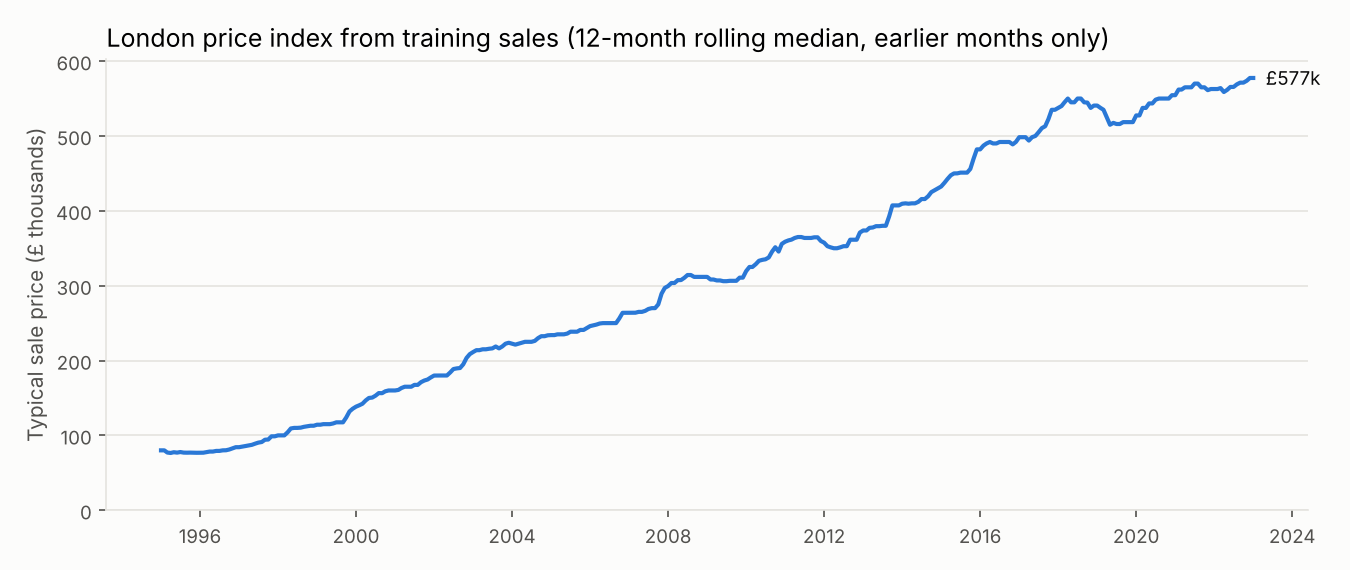

In [3]:
index_table = pd.read_csv(REPORT_DIR / 'price_index.csv')
print(index_table.iloc[::60].to_string(index=False))

 sale_year  sale_month  log_price_index  typical_price_gbp
      1995           1        11.289782            80000.0
      2000           1        11.837689           138370.0
      2005           1        12.362961           233973.0
      2010           1        12.674362           319452.0
      2015           1        12.977321           432493.0
      2020           1        13.175803           527447.0


## Previous-sale features
Most properties appear more than once in the data. For each sale, `src/features.py` adds:
- `prev_price`: the property's most recent sale from an **earlier month**
- `prev_price_adjusted`: that price scaled by the price index movement since
- `months_since_prev_sale`: time since that sale

Leakage rules: only sales from strictly earlier months count, and only training prices are ever looked up. The cell below checks this on the validation rows.

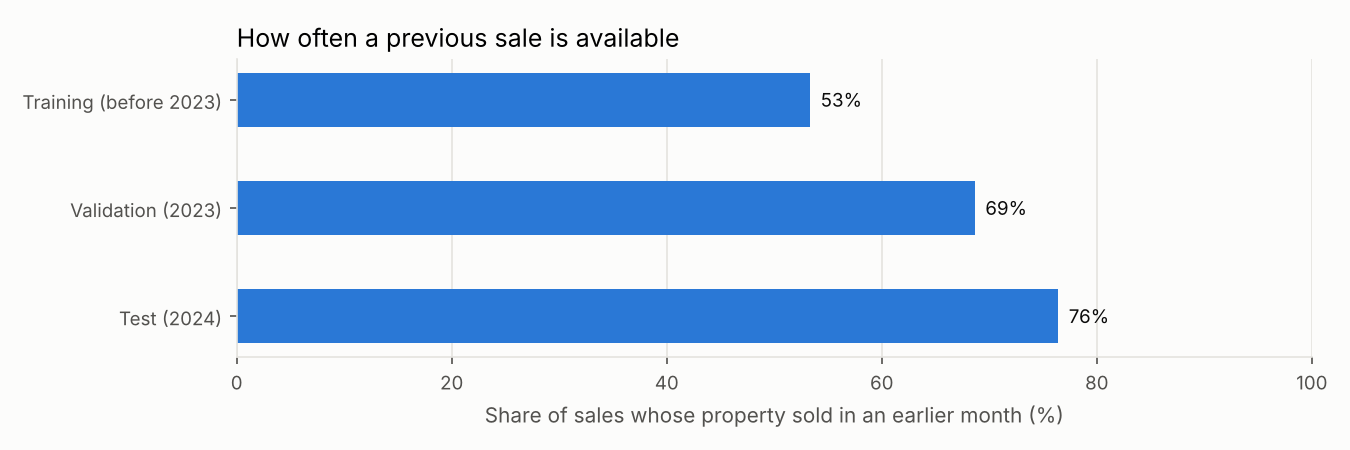

In [4]:
train_f, valid_f = add_previous_sale(train, valid)
has_prev = valid_f['prev_price'].notna()
print(f'Validation rows with a previous sale: {has_prev.mean():.1%}')
violations = (valid_f.loc[has_prev, 'months_since_prev_sale'] < 1).sum()
print(f'Previous sales not from an earlier month: {violations}')
cols = ['price', 'prev_price', 'prev_price_adjusted', 'months_since_prev_sale']
print(valid_f.loc[has_prev, cols].describe().round(0).to_string())

Validation rows with a previous sale: 68.6%
Previous sales not from an earlier month: 0
            price  prev_price  prev_price_adjusted  months_since_prev_sale
count     22929.0     22929.0              22929.0                 22929.0
mean     848600.0    547268.0             865052.0                   139.0
std     1297702.0    944887.0            1258775.0                    85.0
min       10000.0     10000.0              10290.0                     2.0
25%      400000.0    236000.0             420418.0                    70.0
50%      560000.0    380000.0             580482.0                   116.0
75%      880000.0    600000.0             904098.0                   205.0
max    42900000.0  54000000.0           57682812.0                   347.0


## Results
All models use the same training and validation rows. Lower MAE is better.

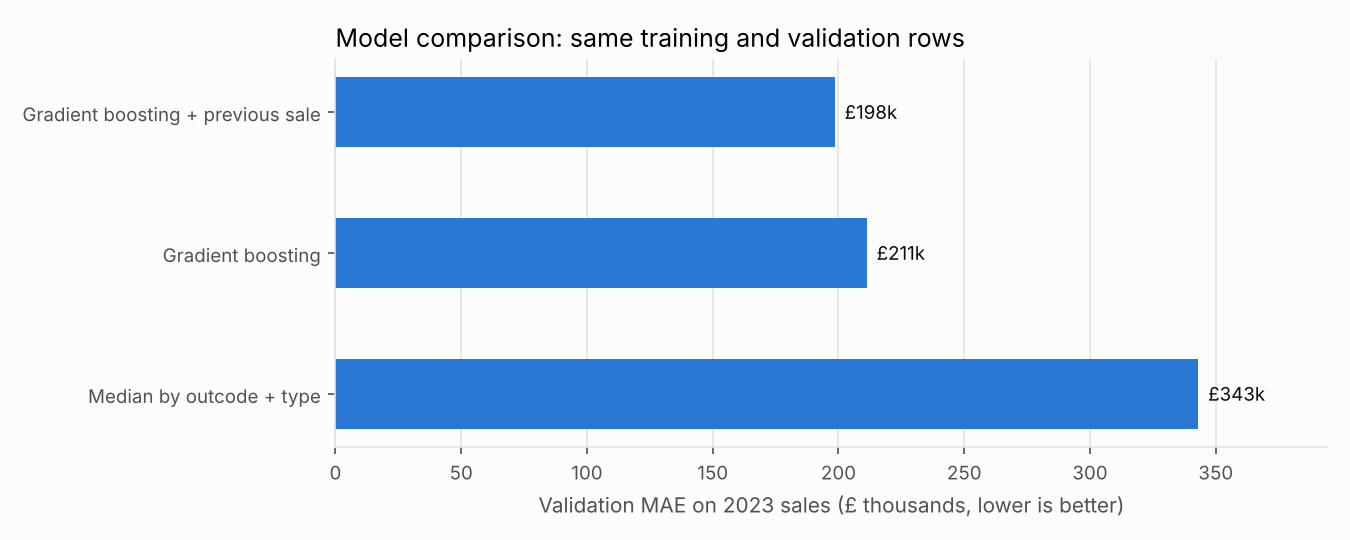

In [5]:
print(pd.read_csv(REPORT_DIR / 'model_comparison.csv').to_string(index=False))
print()
print('Seed check (MAE across random seeds 42, 1, 7):')
print(pd.read_csv(REPORT_DIR / 'seed_check_summary.csv').to_string(index=False))

                            model   mae_gbp  training_rows  validation_rows
         Median by outcode + type 342975.19         232916            33409
                Gradient boosting 211173.51         232916            33409
Gradient boosting + previous sale 198445.72         232916            33409

Seed check (MAE across random seeds 42, 1, 7):
                            model      mean       min       max
                Gradient boosting 210926.77 209976.77 211630.04
Gradient boosting + previous sale 199161.84 198445.72 199987.16


## Conclusions
- Gradient boosting on log price cuts MAE from £343k (median baseline) to £211k.
- Market-adjusted previous-sale features cut it further to about £198k, roughly 6% better. The gain (~£12k) is far larger than run-to-run seed variation (~£1–2k), so it is a real improvement.
- Differences under about £2k between future models should not be treated as improvements without a seed check.
- A teammate's review found two leakage issues in the first version (the index used the sale's own month; same-month repeat sales lost older history). Both are fixed; the score barely changed, but the result can now be trusted.

**Limits:** 2023 was used to make design choices, so it is development evidence rather than a final test. About a quarter of test properties have no previous sale and rely on the other features only.